## Quadro completo del Notebook 2

- **Titolo — Notebook 2: Addestramento U-Net e calibrazione della soglia**
    - Contesto nella pipeline (NB1 $\to$ NB2 $\to$ NB3), split per simulazione, numeri di riferimento (val AP $= 0.8464$, checkpoint EMA epoca 17)
- **Sezione 1 — Setup: percorsi, split, determinismo**
    - 1.1 Librerie, parametri globali e salvataggio di `config.json`
    - 1.2 Determinismo (`torch.use_deterministic_algorithms`, cuDNN deterministico)
    - 1.3 Split per simulazione e congelamento di LH_106 (`RUN_TEST=False`)
- **Sezione 2 — Caricamento dati e sbilanciamento di classe**
    - 2.1 Caricamento patch in `mmap_mode="r"`
    - 2.2 Sbilanciamento ($0.29\%$ positivi sul train) e BCE pesata con $w = N_{\mathrm{neg}}/N_{\mathrm{pos}} \approx 342.5$
- **Sezione 3 — Architettura: una U-Net minimale (1.93M parametri)**
    - 3.1 Motivazione (`base_ch = 32`, `depth = 3`) e scelta delle skip connections
    - 3.2 `DoubleConv` con BatchNorm e `ConvTranspose2d` per l'upsampling
- **Sezione 4 — Exponential Moving Average e loss**
    - 4.1 EMA dei pesi ($d = 0.995$) e warm-up $d_{\mathrm{eff}} = \min(d, (1+t)/(10+t))$
    - 4.2 EMA dei buffer BN (`running_mean`, `running_var`), copia di `num_batches_tracked`
- **Sezione 5 — Metriche di valutazione**
    - 5.1 AP (threshold-free), soft-Dice, IoU@0.5
    - 5.2 Perché AP e non IoU@0.5 come criterio di selezione del checkpoint
- **Sezione 6 — Training: cosine LR, early stopping su val AP, checkpoint EMA**
    - 6.1 Scheduler cosine ($\eta_0 = 10^{-3}$, $\eta_{\min} = 10^{-5}$, $E_{\max} = 20$)
    - 6.2 Early stopping (`PATIENCE = 20`) e best checkpoint EMA
    - 6.3 Output: `config.json`, `history.json`, `best_model.pt`
- **Sezione 7 — Inferenza su LH_105 e ricostruzione delle fette $1024^2$**
    - 7.1 `tiles_to_slices`: indice patch $= s \cdot 16 + g_y \cdot 4 + g_x$
    - 7.2 Interfaccia NB2 $\to$ NB3: `val_prob_slices.npy` (25 fette $1024^2$)
- **Sezione 8 — Metriche a livello oggetto: dal pixel all'alone**
    - 8.1 `blob_catalogue` (esclusione blob al bordo) e `match_blobs` (floor $3\,\mathrm{px}$)
    - 8.2 Completeness, purity, F1 object, area_ratio (2D)
- **Sezione 9 — Sweep della soglia a livello oggetto (nessuna scelta a priori)**
    - 9.1 7 soglie $[0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.99]$ su LH_105
    - 9.2 Massimo di F1 object a $t = 0.99$ ma nessuna scelta operativa qui
- **Sezione 10 — Salvataggio: il contratto NB2 $\to$ NB3**
    - 10.1 File scritti: `threshold_sweep.json`, `candidate_thresholds.json`
    - 10.2 `chosen_threshold.json` **non** scritto da NB2 (spetta a NB3)
- **Sezione 11 — Completeness per taglia di alone**
    - 11.1 5 bin di area $[0, 5, 17, 65, 257, \infty)$ in $\mathrm{px}^2$ (raggio equivalente $[0, 1.3, 2.3, 4.5, 9.0, \infty)$ px)
    - 11.2 Confronto delle 4 candidate: a $t = 0.99$ la classe $\le 4\,\mathrm{px}^2$ crolla a $C = 0.351$
- **Sezione 12 — Controllo visivo per ogni candidate**
    - 12.1 Patch povere, medie, ricche (quantili $25\%$, $75\%$, $100\%$ di `frac = sum(Y)`)
    - 12.2 Layout $3\times3$: input, probabilità, overlay (nero = GT, rosso = predizione)
- **Sezione 12b — Confronto visivo delle 4 soglie su patch identiche**
    - 12b.1 Griglia $4\times3$ (righe = soglie, colonne = patch) per illustrare il trade-off $C$ vs $P$
    - 12b.2 Figura di riferimento per il capitolo Metodi/Risultati

# Notebook 2 — Addestramento U-Net e calibrazione della soglia

Questo notebook addestra la U-Net che segmenta gli aloni di materia oscura sulle mappe SPH proiettate prodotte dal Notebook 1, e produce le probabilità per-pixel che il Notebook 3 trasformerà in un catalogo fisico 3D.

**Ruolo nella pipeline**

| Stadio | Input | Output |
|---|---|---|
| NB1 (`make_input_patches`) | snapshot CAMELS + catalogo FoF | 400 patch 256² per simulazione, normalizzate |
| **NB2 (questo)** | patch LH_100–105 | checkpoint EMA, `val_prob_slices.npy` (25×1024²), `candidate_thresholds.json` |
| NB3 (`vera_conn`) | probabilità + densità ricostruita | catalogo 3D $(x,y,z,M)$ con linking e matching FoF |

**Split per simulazione.** Train: LH_100–104 (2000 patch). Validation: LH_105 (400 patch). Test: LH_106, congelato (`RUN_TEST=False`) finché modello e soglia non sono definitivamente fissati. Lo split è per **simulazione** e non per patch: mescolare patch della stessa simulazione tra train e val produrrebbe data leakage (pixel adiacenti, stessa storia di formazione), gonfiando artificialmente l'AP.

**Numeri di riferimento (run corrente).** Val AP $= 0.8464$ (best epoch 17, checkpoint EMA). Il modello ha 1.93M parametri. La configurazione operativa $(t^*, \text{area}^*)$ **non** viene scelta qui: la scelta finale è in NB3 dopo la griglia $4\times3$, perché dipende anche da linking e matching 3D.

In [1]:
# ============================================================
# 1 — SETUP: librerie, configurazione, determinismo
# ============================================================
import os, json, math, time, copy, random
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
from sklearn.metrics import average_precision_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

In [2]:
# ---------------- percorsi (Colab; ramo locale) ----------------
try:
    from google.colab import drive                                #type: ignore
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/CAMELS_data'
    RUN_ROOT = '/content/drive/MyDrive/unet'
except ImportError:
    DATA_DIR = r"C:\Users\kekko\Downloads\Python\TESI\CAMELS_data"
    RUN_ROOT = os.path.join(DATA_DIR, "unet")

IN_ROOT  = os.path.join(DATA_DIR, "input_data")
RUN_NAME = "unet"

# ---------------- split per SIMULAZIONE ----------------
SPLIT    = {"train": ["LH_100", "LH_101", "LH_102", "LH_103", "LH_104"],
            "val":   ["LH_105"],
            "test":  ["LH_106"]}
SNAP_TAG = "090"

# ---------------- griglia / modello / training ----------------
IMG_SIZE, PATCH_SIZE, N_SLICES = 1024, 256, 25
BASE_CH, DEPTH = 32, 3
BATCH_SIZE, MAX_EPOCHS, PATIENCE = 8, 20, 20
LR, LR_MIN, WEIGHT_DECAY = 1e-3, 1e-5, 1e-4
EMA_DECAY = 0.995

# ---------------- metriche oggetto ----------------
MATCH_TOL_PX = 3.0
RUN_TEST     = False     # True UNA sola volta, con modello e soglia congelati

# ---------------- sweep soglia (object-level) ----------------
SOGLIE_SWEEP         = [0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.99]
CANDIDATE_THRESHOLDS = [0.85, 0.90, 0.95, 0.99]   # portate a nb3

# ---------------- determinismo completo ----------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False
torch.use_deterministic_algorithms(True, warn_only=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | device: {DEVICE}")
print(f"determinismo: cudnn.deterministic=True, cudnn.benchmark=False")
print(f"sweep: {SOGLIE_SWEEP}")
print(f"candidate per nb3: {CANDIDATE_THRESHOLDS}")

torch 2.14.1+cpu | device: cpu
determinismo: cudnn.deterministic=True, cudnn.benchmark=False
sweep: [0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]
candidate per nb3: [0.85, 0.9, 0.95, 0.99]


## 2. Caricamento dati e sbilanciamento di classe

**Il problema centrale: lo sbilanciamento.** Sul train i pixel positivi (dentro un alone sopra `MASS_CUT`) sono lo **0.29%** del totale; sul val lo 0.41%. Una BCE non pesata collasserebbe banalmente sulla classe maggioritaria: predicendo "nessun alone" ovunque si otterrebbe un'accuracy del 99.7%, inutile.

La BCE pesata riequilibra il contributo delle due classi nel gradiente:

$$
\mathcal{L} = -\frac{1}{N}\sum_{i=1}^{N} \left[ w\, y_i \log \sigma(z_i) + (1-y_i)\log\left(1-\sigma(z_i)\right) \right], \qquad w = \frac{N_{\rm neg}}{N_{\rm pos}}
$$

Con $N_{\rm pos} = 0.0029 \cdot N$, si ottiene $w \approx 342.5$. Il peso è calcolato **solo sul train**: il val serve a misurare la generalizzazione, non a calibrare la loss. Se si usasse il val per fissare $w$, l'AP di validazione sarebbe ottimisticamente biased.

**Attenzione al valore di $w$.** 342.5 è alto ma non patologico per segmentazione densa. Valori $> 1000$ (tipici di dataset medici con lesioni rarissime) richiedono tecniche più sofisticate (focal loss, hard negative mining). 

In [3]:
# ============================================================
# 2 — CARICAMENTO DATI (split per simulazione, test mai caricato)
# ============================================================
def sim_dir(run):
    return os.path.join(IN_ROOT, f"sim_{run}_{SNAP_TAG}")

def load_split(runs):
    """Carica X e Y delle simulazioni di un ruolo. Ordine patch: indice = slice*16 + gy*4 + gx."""
    X, Y = [], []
    for run in runs:
        d = sim_dir(run)
        if not os.path.exists(os.path.join(d, "X_patches.npy")):
            raise FileNotFoundError(f"{d}: patch mancanti (eseguire nb1)")
        X.append(np.load(os.path.join(d, "X_patches.npy"), mmap_mode="r"))
        Y.append(np.load(os.path.join(d, "Y_mask_patches.npy"), mmap_mode="r"))
    return (np.concatenate(X).astype(np.float32),
            np.concatenate(Y).astype(np.float32))

data = {}
for role, runs in SPLIT.items():
    if role == "test":
        continue
    X, Y = load_split(runs)
    data[role] = {"X": X, "Y": Y}
    print(f"{role:>5}: {len(X)} patches {runs} | pixel positivi: {100 * Y.mean():.2f}%")

pos = float(data["train"]["Y"].sum())
POS_WEIGHT = (data["train"]["Y"].size - pos) / max(pos, 1.0)
print(f"pos_weight (train): {POS_WEIGHT:.1f}")

LOADERS = {role: DataLoader(TensorDataset(torch.from_numpy(np.ascontiguousarray(d["X"])),
                                          torch.from_numpy(np.ascontiguousarray(d["Y"]))),
                            batch_size=BATCH_SIZE, shuffle=(role == "train"), pin_memory=True)
           for role, d in data.items()}

train: 2000 patches ['LH_100', 'LH_101', 'LH_102', 'LH_103', 'LH_104'] | pixel positivi: 0.29%
  val: 400 patches ['LH_105'] | pixel positivi: 0.41%
pos_weight (train): 342.5


## 3. Architettura: una U-Net minimale (1.93M parametri)

La segmentazione di aloni è un problema **denso** (una predizione per pixel) con strutture a due scale molto diverse:

- il **core** dell'alone: alta densità, pochi pixel, morfologia compatta;
- il **background diffuso**: bassa densità, moltissimi pixel, struttura a larga scala.

Una U-Net con skip connections è la scelta naturale: il ramo encoder (downsampling) cattura il contesto a larga scala, il ramo decoder (upsampling) recupera la localizzazione fine, e le skip connections trasportano l'informazione ad alta frequenza dal contratto all'espansione.

**Perché minimale.** La configurazione è `base_ch=32`, `depth=3` ($1.93$ M parametri). Il numero di patch di training (2000) è piccolo per una rete più profonda: una U-Net standard `base=64, depth=4` ($\sim 8$ M parametri) andrebbe in overfitting già nelle prime epoche, con AP di validazione che degrada mentre il train loss continua a scendere. Il collo di bottiglia non è la capacità del modello, è la statistica del training set.

**Scelte implementative.** `DoubleConv` usa `BatchNorm` dopo ogni convoluzione per stabilizzare il gradiente con $w=342.5$. `ConvTranspose2d` con stride 2 per l'upsampling, con `F.interpolate` di fallback se le dimensioni non combaciano (utile se in futuro si usassero `IMG_SIZE` non multiple di $2^{\rm depth}$).

In [4]:
# ============================================================
# 3 — MODELLO U-Net minimal (~1.93M parametri)
# ============================================================
class DoubleConv(nn.Sequential):
    def __init__(self, c_in, c_out):
        super().__init__(
            nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
            nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False),
            nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))

class Down(nn.Sequential):
    def __init__(self, c_in, c_out):
        super().__init__(nn.MaxPool2d(2), DoubleConv(c_in, c_out))

class Up(nn.Module):
    def __init__(self, c_in):
        super().__init__()
        self.up = nn.ConvTranspose2d(c_in, c_in // 2, 2, stride=2)
        self.conv = DoubleConv(c_in, c_in // 2)
    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.conv(torch.cat([skip, x], dim=1))

class UNet(nn.Module):
    def __init__(self, in_ch=1, base=BASE_CH, depth=DEPTH):
        super().__init__()
        chans = [base * 2**i for i in range(depth + 1)]
        self.inc   = DoubleConv(in_ch, chans[0])
        self.downs = nn.ModuleList(Down(chans[i], chans[i + 1]) for i in range(depth))
        self.ups   = nn.ModuleList(Up(chans[depth - i]) for i in range(depth))
        self.outc  = nn.Conv2d(base, 1, 1)
    def forward(self, x):
        skips = []
        x = self.inc(x)
        for down in self.downs:
            skips.append(x); x = down(x)
        for up, skip in zip(self.ups, reversed(skips)):
            x = up(x, skip)
        return self.outc(x)

model = UNet().to(DEVICE)
print(f"Parametri U-Net: {sum(p.numel() for p in model.parameters()):,}")

Parametri U-Net: 1,926,433


## 4. Exponential Moving Average e loss

**Perché EMA.** Il modello "fresco" ha pesi che oscillano epoca per epoca, soprattutto con LR alto ($10^{-3}$) e BatchNorm. Il checkpoint salvato a fine epoca può essere momentaneamente peggiore di quello dell'epoca precedente anche se la tendenza è in miglioramento. La media esponenziale dei pesi

$$
\theta_{\rm EMA} \leftarrow d\,\theta_{\rm EMA} + (1-d)\,\theta, \qquad d = 0.995
$$

produce un modello "smussato" che generalizza meglio. Il decay $0.995$ corrisponde a una finestra effettiva di $\sim 200$ update: con 250 step per epoca ($2000/8$), la media copre circa un'epoca.

In [5]:
# ============================================================
# 4 — EMA (buffer BN corretti) + loss
# ============================================================
class EMA:
    """Exponential Moving Average. v2: media anche i buffer float (running_mean/var);
    copia i buffer interi (num_batches_tracked). Evita l'incoerenza
    'pesi smussati + statistiche BN del modello fresco'."""
    def __init__(self, model, decay):
        self.decay, self.step = decay, 0
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model):
        self.step += 1
        d = min(self.decay, (1.0 + self.step) / (10.0 + self.step))
        for e, p in zip(self.module.parameters(), model.parameters()):
            e.mul_(d).add_(p.detach(), alpha=1.0 - d)
        for e, b in zip(self.module.buffers(), model.buffers()):
            if e.dtype.is_floating_point:
                e.mul_(d).add_(b.detach(), alpha=1.0 - d)   # media running_mean/var
            else:
                e.copy_(b)                                   # copia num_batches_tracked

ema = EMA(model, EMA_DECAY)
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([POS_WEIGHT], device=DEVICE))
print(f"Loss: BCE con pos_weight={POS_WEIGHT:.1f}")

Loss: BCE con pos_weight=342.5


## 5. Metriche di valutazione

Con lo 0.29% di pixel positivi, l'**accuracy** è inutile: un predittore che dice sempre "no" ha accuracy $99.7\%$. Servono metriche che misurino la capacità di trovare i rari positivi.

**Metriche usate.**

- **AP (Average Precision)**: area sotto la curva precision–recall, integrata su tutte le soglie. Riassume la qualità del ranking delle probabilità. È la metrica di **selezione del checkpoint** (early stopping): non richiede di scegliere una soglia a priori.
- **soft-Dice**: $2\sum p_i y_i / (\sum p_i + \sum y_i)$, versione continua del Dice coefficient. Misura la sovrapposizione tra probabilità predetta e maschera vera.
- **IoU@0.5**: intersezione su unione binarizzando a soglia 0.5. Sanity check qualitativo.

**Perché AP e non IoU@0.5 come criterio di selezione.** La soglia operativa sarà scelta in **NB3** dopo la griglia $4\times3$, non qui. Se avessi selezionato il checkpoint su IoU@0.5, avrei implicitamente introdotto un bias verso la soglia 0.5 — che non è la configurazione operativa. L'AP è threshold-free, coerente con la separazione dei ruoli tra NB2 (rete) e NB3 (catalogo).

**Gestione del rumore numerico.** Soft-Dice e IoU hanno $+1$ al numeratore e al denominatore per evitare divisioni per zero su batch vuoti (nessun pixel positivo). L'AP è calcolato sull'intero set di validazione concatenando le probabilità di tutti i batch, non mediando gli AP per batch: la media di AP è distorta quando i batch hanno sbilanciamenti diversi.

In [6]:
# ============================================================
# 5 — EVALUATE e TRAIN STEP
# ============================================================
@torch.no_grad()
def evaluate(net, loader):
    """Loss, soft-Dice, IoU@0.5, AP (threshold-free) sull'intero set."""
    net.eval()
    tot, n = 0.0, 0
    s_p = s_y = s_py = 0.0
    tp = fp = fn = 0.0
    probs, truths = [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = net(xb)
        tot += criterion(logits, yb).item() * len(xb); n += len(xb)
        p = torch.sigmoid(logits)
        s_p += float(p.sum()); s_y += float(yb.sum()); s_py += float((p * yb).sum())
        b = p > 0.5; ym = yb.bool()
        tp += float((b & ym).sum()); fp += float((b & ~ym).sum()); fn += float((~b & ym).sum())
        probs.append(p.float().cpu().numpy().ravel())
        truths.append(yb.cpu().numpy().ravel())
    return {"loss": tot / n,
            "soft_dice": (2 * s_py + 1) / (s_p + s_y + 1),
            "iou50": tp / max(tp + fp + fn, 1.0),
            "ap": float(average_precision_score(np.concatenate(truths),
                                                np.concatenate(probs)))}

def train_one_epoch(net, loader, optimizer):
    net.train()
    tot, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(net(xb), yb)
        loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        optimizer.step()
        ema.update(net)
        tot += loss.item() * len(xb); n += len(xb)
    return tot / n

def lr_at(epoch0):
    progress = epoch0 / max(1, MAX_EPOCHS - 1)
    return LR_MIN + 0.5 * (LR - LR_MIN) * (1.0 + math.cos(math.pi * progress))

## 6. Training: cosine LR, early stopping su val AP, checkpoint EMA

**Scheduler cosine.** Il learning rate segue

$$
\eta(e) = \eta_{\min} + \tfrac{1}{2}(\eta_0 - \eta_{\min})\left(1 + \cos\frac{\pi e}{E_{\max}-1}\right)
$$

con $\eta_0 = 10^{-3}$, $\eta_{\min} = 10^{-5}$, $E_{\max} = 20$. Il cosine anneal produce un LR che decresce lentamente all'inizio e più rapidamente a metà training, per poi "assestarsi" nelle ultime epoche. Questo permette al modello di raffinare i pesi senza oscillazioni dell'ultimo minuto (tipiche di uno step decay mal calibrato).

**Early stopping.** Il training si interrompe se il val AP non migliora per `PATIENCE = 20` epoche consecutive. Con `MAX_EPOCHS = 20` la patience non scatta mai (al più `bad_epochs` arriva a 3): è una rete di sicurezza se in futuro si aumenta $E_{\max}$.

**Checkpoint.** Il file `best_model.pt` contiene sempre il modello **EMA** all'epoca di miglior val AP. Nel run corrente: epoca 17, val AP $= 0.8464$. Le ultime tre epoche (18, 19, 20) hanno AP leggermente inferiore, segno che il modello ha saturato la capacità.

**Cosa salva il notebook.**

- `config.json`: split, iperparametri, versioni di torch/numpy, device, seed. Documenta *esattamente* cosa ha prodotto un dato checkpoint.
- `history.json`: curve train/val per loss, soft-Dice, IoU, AP. Serve per riprodurre il plot e per eventuali diagnostiche a posteriori.
- `best_model.pt`: checkpoint EMA (solo `state_dict` + epoca + metriche val, per compatibilità tra versioni di torch).

epoch   1/20 | train 0.2583 | val 0.1148 | AP 0.7933 | softDice 0.1174 |     53s  <- best
epoch   2/20 | train 0.1085 | val 0.0714 | AP 0.7961 | softDice 0.2517 |    105s  <- best
epoch   3/20 | train 0.0929 | val 0.0650 | AP 0.8049 | softDice 0.3230 |    163s  <- best
epoch   4/20 | train 0.0804 | val 0.0565 | AP 0.8182 | softDice 0.3687 |    221s  <- best
epoch   5/20 | train 0.0838 | val 0.0580 | AP 0.8111 | softDice 0.3951 |    281s
epoch   6/20 | train 0.1002 | val 0.0546 | AP 0.8241 | softDice 0.3899 |    340s  <- best
epoch   7/20 | train 0.0712 | val 0.0533 | AP 0.8215 | softDice 0.4070 |    398s
epoch   8/20 | train 0.0732 | val 0.0511 | AP 0.8287 | softDice 0.4125 |    458s  <- best
epoch   9/20 | train 0.0746 | val 0.0514 | AP 0.8279 | softDice 0.4111 |    517s
epoch  10/20 | train 0.0656 | val 0.0498 | AP 0.8314 | softDice 0.4239 |    576s  <- best
epoch  11/20 | train 0.0744 | val 0.0494 | AP 0.8335 | softDice 0.4324 |    635s  <- best
epoch  12/20 | train 0.0629 | val 0.0

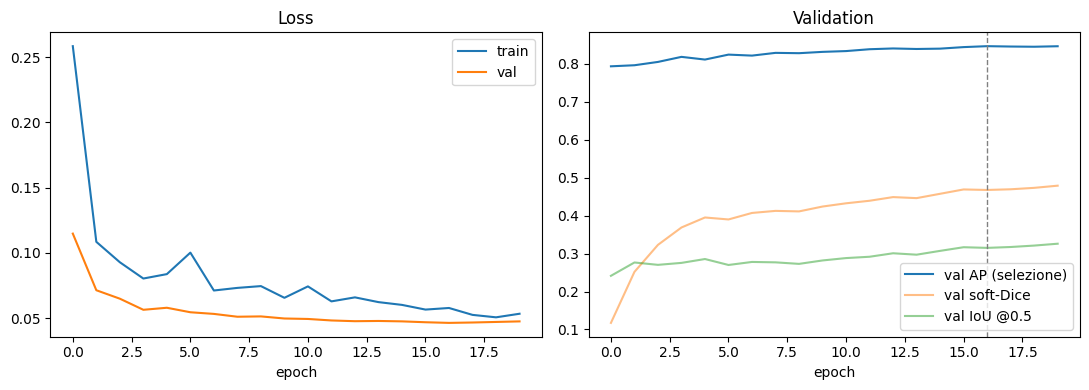

In [7]:
# ============================================================
# 6 — TRAINING LOOP (early stopping su val AP, checkpoint EMA)
# ============================================================
RUN_DIR = os.path.join(RUN_ROOT, RUN_NAME)
os.makedirs(RUN_DIR, exist_ok=True)

# --- config.json (v2: include versioni e device) ---
with open(os.path.join(RUN_DIR, "config.json"), "w") as fh:
    json.dump({
        "split": SPLIT, "pos_weight": POS_WEIGHT,
        "lr": LR, "lr_min": LR_MIN, "max_epochs": MAX_EPOCHS,
        "batch_size": BATCH_SIZE, "base_ch": BASE_CH, "depth": DEPTH,
        "ema_decay": EMA_DECAY, "weight_decay": WEIGHT_DECAY,
        "seed": SEED,
        "torch_version": torch.__version__,
        "cuda_version": torch.version.cuda if torch.cuda.is_available() else None,
        "numpy_version": np.__version__,
        "device_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
        "deterministic": True,
        "sweep_thresholds": SOGLIE_SWEEP,
        "candidate_thresholds": CANDIDATE_THRESHOLDS,
    }, fh, indent=2)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
history = {k: [] for k in ("train_loss", "val_loss", "val_soft_dice", "val_iou50", "val_ap")}
best_score, bad_epochs, best_epoch = -1.0, 0, -1
t0 = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    for g in optimizer.param_groups:
        g["lr"] = lr_at(epoch - 1)
    tr = train_one_epoch(model, LOADERS["train"], optimizer)
    va = evaluate(ema.module, LOADERS["val"])
    for k, v in zip(history, (tr, va["loss"], va["soft_dice"], va["iou50"], va["ap"])):
        history[k].append(float(v))

    marker = ""
    if va["ap"] > best_score:
        best_score, best_epoch, bad_epochs = va["ap"], epoch, 0
        torch.save({"state_dict": ema.module.state_dict(), "epoch": epoch, "val": va},
                   os.path.join(RUN_DIR, "best_model.pt"))
        marker = "  <- best"
    else:
        bad_epochs += 1

    print(f"epoch {epoch:3d}/{MAX_EPOCHS} | train {tr:.4f} | val {va['loss']:.4f} | "
          f"AP {va['ap']:.4f} | softDice {va['soft_dice']:.4f} | {time.time() - t0:6.0f}s{marker}")
    if bad_epochs >= PATIENCE:
        print(f"Early stopping (best epoch: {best_epoch})")
        break

with open(os.path.join(RUN_DIR, "history.json"), "w") as fh:
    json.dump({"history": history, "best_epoch": best_epoch}, fh, indent=2)
print(f"\nDone in {(time.time() - t0) / 60:.1f} min | best epoch {best_epoch} | val AP {best_score:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["train_loss"], label="train"); axes[0].plot(history["val_loss"], label="val")
axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].set_title("Loss")
axes[1].plot(history["val_ap"], label="val AP (selezione)")
axes[1].plot(history["val_soft_dice"], label="val soft-Dice", alpha=0.5)
axes[1].plot(history["val_iou50"], label="val IoU @0.5", alpha=0.5)
axes[1].axvline(best_epoch - 1, color="gray", ls="--", lw=1)
axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].set_title("Validation")
plt.tight_layout(); plt.show()

## 7. Inferenza su LH_105 e ricostruzione delle fette 1024²

La U-Net lavora su patch $256^2$, ma il catalogo fisico di NB3 richiede mappe $1024^2$ per ogni fetta $z$. `tiles_to_slices` ricostruisce la mappa a partire dall'ordine con cui NB1 ha generato le patch:

$$
\text{indice patch} = s \cdot 16 + g_y \cdot 4 + g_x, \qquad s \in [0,24],\ g_x,g_y \in [0,3]
$$

dove $s$ è l'indice di fetta e $(g_x, g_y)$ la posizione della patch nella griglia $4\times4$. L'output è un array `(25, 1024, 1024)` in `float32`.

**Interfaccia NB2 → NB3.** Il file `val_prob_slices.npy` è il contratto tra i due notebook: NB3 non riaddestra, legge le probabilità già calcolate. Nel run corrente contiene le 25 fette di LH_105, predette dal checkpoint EMA all'epoca 17.

**Attenzione per il test set.** `val_prob_slices.npy` è solo per LH_105. Quando si eseguirà LH_106 (`RUN_TEST=True`), servirà una inferenza dedicata: stesso `predict_probs` + `tiles_to_slices`, ma su `X_patches.npy` di `sim_LH_106_090`, salvando in un file separato (es. `test_prob_slices.npy`). Il file di validazione non va sovrascritto.

**Istogramma delle probabilità.** Il plot §7 mostra la distribuzione delle probabilità predette: con una rete ben addestrata ci si aspetta una massa enorme a probabilità $\approx 0$ (background) e una coda a probabilità alte (core degli aloni). Una distribuzione bimodale con valle a metà indica una separazione netta tra le due classi.

checkpoint: epoch 17 | val AP 0.8464
Fette validation: (25, 1024, 1024) -> val_prob_slices.npy


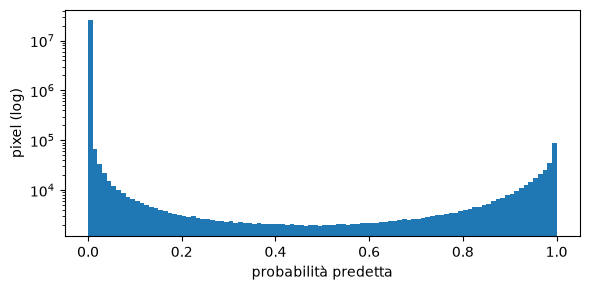

In [7]:
# ============================================================
# 7 — INFERENZA su val + ricostruzione fette 1024²
# ============================================================
RUN_DIR = r"C:\Users\kekko\Downloads\Python\TESI\CAMELS_data\unet"
ckpt = torch.load(os.path.join(RUN_DIR, "best_model.pt"), map_location=DEVICE)
net = UNet().to(DEVICE)
net.load_state_dict(ckpt["state_dict"])
net.eval()
print(f"checkpoint: epoch {ckpt['epoch']} | val AP {ckpt['val']['ap']:.4f}")

@torch.no_grad()
def predict_probs(net, X, batch=16):
    out = []
    for i in range(0, len(X), batch):
        out.append(torch.sigmoid(net(X[i:i + batch].to(DEVICE))).cpu().numpy())
    return np.concatenate(out).astype(np.float32)

def tiles_to_slices(tiles, n_grid=IMG_SIZE // PATCH_SIZE):
    """Ricostruisce fette 1024². Ordine: indice = slice*16 + gy*4 + gx."""
    assert tiles.shape[0] % n_grid ** 2 == 0
    n = tiles.shape[0] // n_grid ** 2
    out = np.empty((n, IMG_SIZE, IMG_SIZE), dtype=tiles.dtype)
    for i in range(n):
        for k in range(n_grid ** 2):
            gy, gx = divmod(k, n_grid)
            out[i, gy*PATCH_SIZE:(gy+1)*PATCH_SIZE, gx*PATCH_SIZE:(gx+1)*PATCH_SIZE] = tiles[i*n_grid**2 + k]
    return out

probs_val = predict_probs(net, torch.from_numpy(np.ascontiguousarray(data["val"]["X"])))
P_val = tiles_to_slices(probs_val[:, 0])                     # (25, 1024, 1024)
Y_val = tiles_to_slices(data["val"]["Y"][:, 0].astype(np.uint8)).astype(bool)
np.save(os.path.join(RUN_DIR, "val_prob_slices.npy"), P_val)
print(f"Fette validation: {P_val.shape} -> val_prob_slices.npy")

plt.figure(figsize=(6, 3))
plt.hist(probs_val.ravel(), bins=100, log=True)
plt.xlabel("probabilità predetta"); plt.ylabel("pixel (log)")
plt.tight_layout(); plt.show()

## 8. Metriche a livello oggetto: dal pixel all'alone

La tesi non è sulla segmentazione: è sul **catalogo di aloni**. Le metriche pixel-level (AP, IoU) sono propedeutiche, ma la valutazione vera avviene a livello oggetto, contando quanti aloni reali vengono trovati e quanti oggetti predetti sono fisicamente sensati.

**Pipeline di valutazione.**

1. **Binarizzazione** a soglia $t$ e labeling con connettività 8.
2. **`blob_catalogue`**: per ogni componente connessa calcola centroide $(c_y, c_x)$ e area $A$. **Esclude i blob al bordo**: la periodicità del box è gestita in NB3 col mosaico $3\times3$, qui il tile romperebbe la continuità e falserebbe il centroide.
3. **`match_blobs`**: matching greedy 1-a-1 tra GT e predetti. Un match è accettato se

$$
d \le \max\left(3\,{\rm px},\ r_{\rm eq}^{\rm GT}\right), \qquad r_{\rm eq}^{\rm GT} = \sqrt{A_{\rm GT}/\pi}
$$

Il floor di $3\,{\rm px}$ evita che aloni molto piccoli ($A < 28\,{\rm px}^2$, $r_{\rm eq}<3\,{\rm px}$) matchino solo per coincidenza geometrica.

**Metriche derivate.**

- **completeness** $C_{\rm 2D} = N_{\rm match}/N_{\rm GT}$: frazione di aloni veri trovati.
- **purity** $P_{\rm 2D} = N_{\rm match}/N_{\rm pred}$: frazione di predizioni che corrispondono a un alone vero.
- **F1 object** $= 2 C_{\rm 2D} P_{\rm 2D} / (C_{\rm 2D} + P_{\rm 2D})$.
- **area_ratio** $= \sum A_{\rm pred} / \sum A_{\rm GT}$: se $>1$ la rete "sbava" oltre il bordo dell'alone, se $<1$ lo sottosegmenta.

Queste metriche sono **più severe** di quelle di NB3: NB3 ha linking 3D e matching con $R_{200}$ (tolleranza fisica), qui il matching è puramente geometrico in 2D. Servono a valutare la rete *isolatamente*, prima del post-processing.

In [8]:
# ============================================================
# 8 — METRICHE OGGETTO
# ============================================================
SIZE_EDGES  = [0, 5, 17, 65, 257, 10**9]
SIZE_LABELS = ["<=4 px", "5-16", "17-64", "65-256", ">256"]
STRUCT8 = np.ones((3, 3), bool)

def blob_catalogue(lab, n):
    """(cy, cx, area) per ogni componente; esclusi blob al bordo (periodicità rotta)."""
    if n == 0:
        return []
    H, W = lab.shape
    sizes = np.bincount(lab.ravel(), minlength=n + 1)[1:]
    coms  = ndimage.center_of_mass(np.ones_like(lab), lab, range(1, n + 1))
    sl    = ndimage.find_objects(lab)
    return [(coms[i][0], coms[i][1], int(sizes[i])) for i in range(n)
            if not (sl[i][0].start == 0 or sl[i][1].start == 0
                    or sl[i][0].stop == H or sl[i][1].stop == W)]

def match_blobs(gt, pr, tol_px):
    """Matching greedy 1-a-1. Match se d <= max(tol_px, r_eq_GT)."""
    cand = []
    for i, (cy, cx, a) in enumerate(gt):
        tol = max(tol_px, math.sqrt(a / math.pi))
        for j, (py, px, _) in enumerate(pr):
            d = math.hypot(cy - py, cx - px)
            if d <= tol:
                cand.append((d, i, j))
    cand.sort()
    used_i, used_j, pairs = set(), set(), []
    for d, i, j in cand:
        if i not in used_i and j not in used_j:
            used_i.add(i); used_j.add(j); pairs.append((i, j))
    return pairs

def metrics_from_counts(rows):
    tp, fp, fn = rows[:, :3].sum(0)
    ngt, npr, nm = rows[:, 3:].sum(0)
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    comp, pur = nm / max(ngt, 1), nm / max(npr, 1)
    return {"prec_pix": prec, "rec_pix": rec, "iou": tp / max(tp + fp + fn, 1),
            "f1_pix": 2 * prec * rec / max(prec + rec, 1e-9),
            "area_ratio": (tp + fp) / max(tp + fn, 1.0),
            "n_gt": int(ngt), "n_pred": int(npr), "n_match": int(nm),
            "completeness": comp, "purity": pur,
            "f1_obj": 2 * comp * pur / max(comp + pur, 1e-9)}

def eval_objects(y_slices, p_slices, t, gt_records=False):
    rows, bins = [], [[] for _ in SIZE_LABELS]
    for y_i, p_i in zip(y_slices, p_slices):
        b = p_i > t
        gtl, n1 = ndimage.label(y_i, STRUCT8)
        prl, n2 = ndimage.label(b,    STRUCT8)
        gt, pr = blob_catalogue(gtl, n1), blob_catalogue(prl, n2)
        matched = {i for i, _ in match_blobs(gt, pr, MATCH_TOL_PX)}
        rows.append(((b & y_i).sum(), (b & ~y_i).sum(), (~b & y_i).sum(),
                     len(gt), len(pr), len(matched)))
        if gt_records:
            for k, (_, _, a) in enumerate(gt):
                bins[int(np.searchsorted(SIZE_EDGES, a, "right")) - 1].append(k in matched)
    rows = np.array(rows, float)
    m = metrics_from_counts(rows)
    if gt_records:
        m["comp_by_size"] = [float(np.mean(v)) if v else np.nan for v in bins]
        m["n_by_size"]    = [len(v) for v in bins]
    return m, rows

## 9. Sweep della soglia a livello oggetto (nessuna scelta a priori)

La soglia $t$ binarizza le probabilità: valori alti producono pochi oggetti "core", valori bassi producono molti oggetti "sbavati". Lo sweep valuta **7 soglie** $[0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.99]$ su LH_105 con le metriche oggetto di §8.

**Cosa ci si aspetta.**

| Comportamento | Soglia bassa | Soglia alta |
|---|---|---|
| completeness | alta (tutti gli aloni "accesi") | bassa (solo core densi) |
| purity | bassa (frammenti di rumore) | alta (solo oggetti solidi) |
| area_ratio | $\gg 1$ (sbavatura) | $\approx 1$ (core) |
| F1 object | massimo intermedio | massimo a soglia alta |

Nel run corrente il **massimo di F1 object è a $t = 0.99$** ($F1 = 0.829$), trainato dalla purity elevata ($0.794$). **Ma questo non significa che 0.99 sia la configurazione operativa.** Lo sweep è object-level 2D su patch; NB3 mostrerà che con linking 3D e matching fisico la completeness massima si ottiene a $t = 0.95$ ($C = 0.818$), perché a 0.99 si perdono gli aloni deboli.

**Perché nessuna linea verticale "di scelta" nei plot.** La configurazione $(t^*, \text{area}^*)$ dipende anche dal filtro d'area 3D e dal linking, che sono parametri di NB3. Sceglierla qui significherebbe "sposare" una soglia prima di aver visto l'effetto del post-processing. Le 4 candidate $[0.85, 0.90, 0.95, 0.99]$ vengono passate a NB3, che deciderà sulla base della griglia $4\times3$.

Sweep oggetto — 7 soglie (nessun t* scelto a priori)

    t  n_pred  completeness  purity  f1_obj  area_ratio   iou  f1_pix  prec_pix  rec_pix
0.700    9415         0.835   0.384   0.526       3.117 0.320   0.485     0.320    0.998
0.750    9355         0.843   0.390   0.534       2.981 0.334   0.501     0.335    0.998
0.800    9183         0.852   0.402   0.546       2.817 0.353   0.522     0.354    0.997
0.850    8902         0.867   0.422   0.568       2.608 0.380   0.551     0.381    0.994
0.900    8449         0.889   0.456   0.603       2.301 0.427   0.599     0.429    0.988
0.950    7414         0.924   0.540   0.682       1.769 0.529   0.692     0.542    0.959
0.990    4730         0.867   0.794   0.829       0.843 0.550   0.710     0.776    0.654

Sottoinsieme candidate per nb3 ([0.85, 0.9, 0.95, 0.99]):
    t  n_pred  completeness  purity  f1_obj  area_ratio
0.850    8902         0.867   0.422   0.568       2.608
0.900    8449         0.889   0.456   0.603       2.301
0.950  

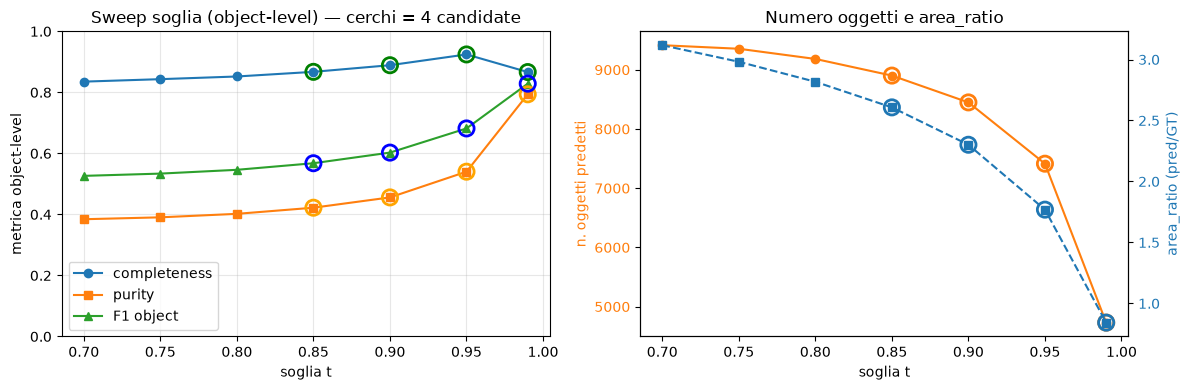

In [9]:
# ============================================================
# 9 — SWEEP SOGLIA object-level (7 soglie) — nessuna scelta a priori
# ============================================================
rows_sweep = []
for t in SOGLIE_SWEEP:
    m, _ = eval_objects(Y_val, P_val, float(t))
    rows_sweep.append({"t": float(t), **m})
df_sweep = pd.DataFrame(rows_sweep)

# --- tabella completa (tutte le metriche per tutte le soglie) ---
print("Sweep oggetto — 7 soglie (nessun t* scelto a priori)\n")
cols_show = ["t", "n_pred", "completeness", "purity", "f1_obj",
             "area_ratio", "iou", "f1_pix", "prec_pix", "rec_pix"]
print(df_sweep[cols_show].to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# --- tabella ridotta: solo le 4 candidate (che porti a nb3) ---
df_cand = df_sweep[df_sweep["t"].isin(CANDIDATE_THRESHOLDS)].copy()
print(f"\nSottoinsieme candidate per nb3 ({CANDIDATE_THRESHOLDS}):")
print(df_cand[["t", "n_pred", "completeness", "purity", "f1_obj", "area_ratio"]]
      .to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# --- plot: due viste ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# (a) object-level: C, P, F1_obj — nessuna linea verticale "di scelta"
axes[0].plot(df_sweep["t"], df_sweep["completeness"], "o-", label="completeness")
axes[0].plot(df_sweep["t"], df_sweep["purity"],       "s-", label="purity")
axes[0].plot(df_sweep["t"], df_sweep["f1_obj"],       "^-", label="F1 object")
# evidenzia le 4 candidate con marker più grandi
axes[0].scatter(df_cand["t"], df_cand["completeness"], s=120, facecolors="none", edgecolors="green",  linewidths=2, zorder=5)
axes[0].scatter(df_cand["t"], df_cand["purity"],       s=120, facecolors="none", edgecolors="orange", linewidths=2, zorder=5)
axes[0].scatter(df_cand["t"], df_cand["f1_obj"],       s=120, facecolors="none", edgecolors="blue",   linewidths=2, zorder=5)
axes[0].set_xlabel("soglia t"); axes[0].set_ylabel("metrica object-level")
axes[0].set_ylim(0, 1); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title("Sweep soglia (object-level) — cerchi = 4 candidate")

# (b) n_pred e area_ratio (trade-off)
ax2 = axes[1]
ax2.plot(df_sweep["t"], df_sweep["n_pred"], "o-", color="tab:orange", label="n_pred")
ax2.scatter(df_cand["t"], df_cand["n_pred"], s=120, facecolors="none", edgecolors="tab:orange", linewidths=2, zorder=5)
ax2.set_xlabel("soglia t"); ax2.set_ylabel("n. oggetti predetti", color="tab:orange")
ax2.tick_params(axis="y", labelcolor="tab:orange")

ax3 = ax2.twinx()
ax3.plot(df_sweep["t"], df_sweep["area_ratio"], "s--", color="tab:blue")
ax3.scatter(df_cand["t"], df_cand["area_ratio"], s=120, facecolors="none", edgecolors="tab:blue", linewidths=2, zorder=5)
ax3.set_ylabel("area_ratio (pred/GT)", color="tab:blue")
ax3.tick_params(axis="y", labelcolor="tab:blue")
ax2.set_title("Numero oggetti e area_ratio")
plt.tight_layout(); plt.show()

## 10. Salvataggio: il contratto NB2 → NB3

Questo notebook produce **tre** file, e ne lascia esplicitamente fuori **uno**.

**Scritti da NB2.**

- `threshold_sweep.json`: lo sweep completo a 7 soglie, con tutte le metriche object-level (completeness, purity, F1, area_ratio, IoU, precision, recall per pixel). Serve per ricostruire il plot di §9 e per eventuali analisi a posteriori.
- `candidate_thresholds.json`: le 4 candidate $[0.85, 0.90, 0.95, 0.99]$ + lo sweep completo + una nota esplicita `"no_chosen_yet": true`. È il file che NB3 legge in input.
- `best_model.pt`, `config.json`, `history.json`: già discussi in §6.

**NON scritto da NB2: `chosen_threshold.json`.**

Il contratto è deliberato: la scelta finale $(t^*, \text{area}^*)$ spetta a NB3, che vede l'effetto del linking 3D e del matching con $R_{200}$. Scriverla qui significherebbe fissare una soglia prima di conoscere il comportamento della pipeline completa. 

In [10]:
# ============================================================
# 10 — SALVATAGGIO (sweep completo + candidate) — nessun t* pre-scelto
# ============================================================
# NESSUN "chosen_threshold.json" scritto qui. Il file sarà scritto SOLO da nb3
# alla fine della griglia 4x3. Questo notebook produce solo:
#   - threshold_sweep.json      : sweep completo (7 soglie, tutte le metriche)
#   - candidate_thresholds.json : le 4 candidate + lo sweep (per nb3)

with open(os.path.join(RUN_DIR, "threshold_sweep.json"), "w") as fh:
    json.dump(rows_sweep, fh, indent=2)

with open(os.path.join(RUN_DIR, "candidate_thresholds.json"), "w") as fh:
    json.dump({
        "candidates":   CANDIDATE_THRESHOLDS,
        "sweep":        rows_sweep,
        "note":         "config operativa (t, area) decisa in nb3 dopo la griglia 4x3",
        "no_chosen_yet": True,
    }, fh, indent=2)

# Se esiste un chosen_threshold.json da run precedenti, NON lo tocchiamo,
# ma lo segnaliamo esplicitamente.
chosen_path = os.path.join(RUN_DIR, "chosen_threshold.json")
if os.path.exists(chosen_path):
    print(f"[NOTA] {chosen_path} esiste già (probabilmente da una run precedente).")
    print(f"       Non lo modifichiamo: sarà sovrascritto da nb3 con la scelta finale.")
else:
    print(f"[NOTA] {chosen_path} non esiste. Sarà creato da nb3 con la scelta finale.")

print(f"\nSalvati:")
print(f"  threshold_sweep.json       ({len(SOGLIE_SWEEP)} soglie)")
print(f"  candidate_thresholds.json  candidate={CANDIDATE_THRESHOLDS}")
print(f"\nNessun valore 'suggested'. La scelta finale è in nb3.")

[NOTA] C:\Users\kekko\Downloads\Python\TESI\CAMELS_data\unet\chosen_threshold.json esiste già (probabilmente da una run precedente).
       Non lo modifichiamo: sarà sovrascritto da nb3 con la scelta finale.

Salvati:
  threshold_sweep.json       (7 soglie)
  candidate_thresholds.json  candidate=[0.85, 0.9, 0.95, 0.99]

Nessun valore 'suggested'. La scelta finale è in nb3.


## 11. Completeness per taglia di alone

La completeness media ($C \approx 0.82$ a $t = 0.95$) non è uniforme: gli aloni piccoli sono intrinsecamente più difficili da segmentare. Un alone con area $A \le 4\,{\rm px}^2$ ha $r_{\rm eq} \le 1.1\,{\rm px}$: appena sopra la risoluzione della mappa, e basta un pixel sotto soglia per perdere l'intero oggetto. Un alone con area $> 256\,{\rm px}^2$ ha $r_{\rm eq} > 9\,{\rm px}$: la statistica dei pixel è sufficiente e la rete lo trova sempre.

I bin di taglia usati sono $[0, 5, 17, 65, 257, \infty)$ in $\rm px^2$, corrispondenti a raggio equivalente $[0, 1.3, 2.3, 4.5, 9.0, \infty)$ $\rm px$.

**Risultati nel run corrente (a $t = 0.95$).**

| area GT $[{\rm px}^2]$ | $r_{\rm eq}$ $[{\rm px}]$ | completeness | n. GT |
|---|---|---|---|
| $\le 4$ | $\le 1.1$ | 0.757 | 37 |
| 5–16 | 1.3–2.3 | 0.912 | 3103 |
| 17–64 | 2.3–4.5 | 0.954 | 961 |
| 65–256 | 4.5–9.0 | 0.984 | 189 |
| $> 256$ | $> 9.0$ | 1.000 | 42 |

**Confronto tra le 4 candidate.** La tabella mostra la completeness per bin alle 4 soglie $[0.85, 0.90, 0.95, 0.99]$. A $t = 0.99$ la classe $\le 4$ px crolla a $C = 0.351$ (la rete perde quasi tutti gli aloni piccoli), mentre le classi grandi restano $\ge 0.99$. È questo il prezzo della soglia alta: non uniforme, concentrato sugli aloni di taglia piccola.

Completeness per taglia di alone (per ogni candidate)

area GT    | t=0.85 | t=0.9  | t=0.95 | t=0.99 | n_GT
-----------------------------------------------------
<=4 px     | 0.919 | 0.919 | 0.757 | 0.351 | 37
5-16       | 0.852 | 0.876 | 0.912 | 0.824 | 3103
17-64      | 0.894 | 0.914 | 0.954 | 0.992 | 961
65-256     | 0.947 | 0.952 | 0.984 | 1.000 | 189
>256       | 1.000 | 0.976 | 1.000 | 1.000 | 42


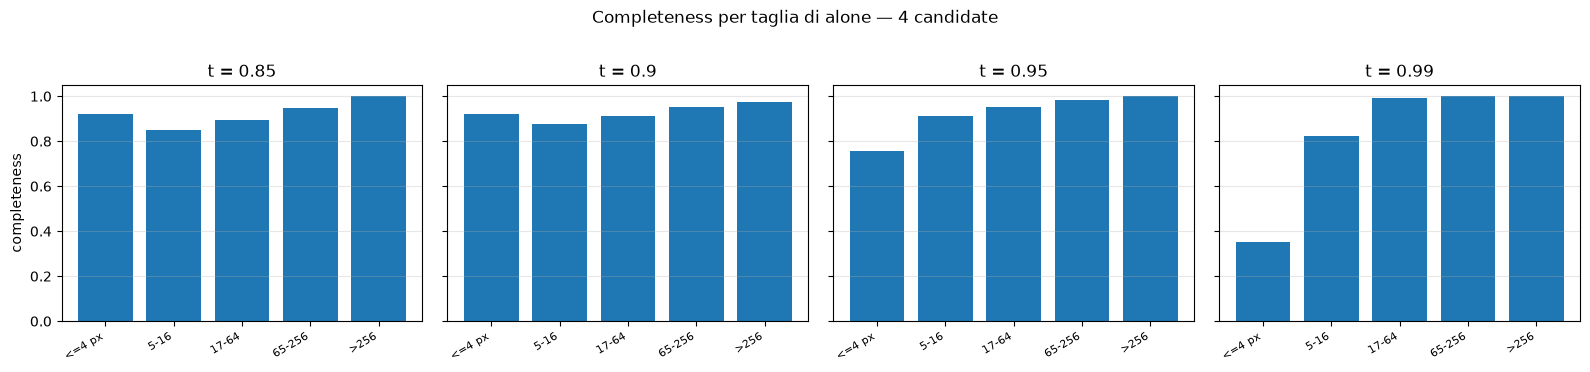

In [11]:
# ============================================================
# 11 — COMPLETENESS PER TAGLIA (per ognuna delle 4 candidate)
# ============================================================
# Tabella: righe = size bin, colonne = 4 t. Più 4 subplot affiancati.
size_results = {}
for t in CANDIDATE_THRESHOLDS:
    m_size, _ = eval_objects(Y_val, P_val, float(t), gt_records=True)
    size_results[t] = m_size

# --- tabella ---
print("Completeness per taglia di alone (per ogni candidate)\n")
header = f"{'area GT':<10} | " + " | ".join(f"t={t:<4}" for t in CANDIDATE_THRESHOLDS) + " | n_GT"
print(header); print("-" * len(header))
for i, lab in enumerate(SIZE_LABELS):
    row = f"{lab:<10} | "
    row += " | ".join(f"{size_results[t]['comp_by_size'][i]:.3f}" for t in CANDIDATE_THRESHOLDS)
    row += f" | {size_results[CANDIDATE_THRESHOLDS[0]]['n_by_size'][i]}"
    print(row)

# --- 4 subplot ---
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, t in zip(axes, CANDIDATE_THRESHOLDS):
    vals = size_results[t]["comp_by_size"]
    ax.bar(range(len(SIZE_LABELS)), vals, color="tab:blue")
    ax.set_xticks(range(len(SIZE_LABELS)))
    ax.set_xticklabels(SIZE_LABELS, rotation=30, ha="right", fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"t = {t}")
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("completeness")
plt.suptitle("Completeness per taglia di alone — 4 candidate", y=1.02)
plt.tight_layout(); plt.show()

## 12. Controllo visivo per ogni candidate

**Layout per ogni soglia $t$.** Griglia $3 \times 3$:

- riga 1: mappa SPH $X$ (input della rete);
- riga 2: mappa di probabilità $P(\rm halo)$ predetta;
- riga 3: overlay con contorni — **nero = GT**, **rosso = predizione binarizzata a $t$**.

**Cosa guardare.**

- **A $t = 0.85$**: i contorni rossi sbavano oltre il GT nero, catturano materia diffusa attorno agli aloni, e compaiono frammenti in zone di rumore. È il segnale visivo dell'`area_ratio` $> 1$ (sbavatura).
- **A $t = 0.95$**: i contorni rossi seguono fedelmente il GT nero sui core, con qualche pixel di bordo mancante. È il compromesso visivo che corrisponde al massimo di completeness 3D in NB3.
- **A $t = 0.99$**: i contorni rossi sono più stretti del GT nero, aloni piccoli scompaiono. È il segnale visivo della completeness per taglia che crolla (classe $\le 4$ px a $C = 0.351$).

Le stesse 3 patch sono usate per tutte le 4 soglie, in modo che il confronto sia diretto.

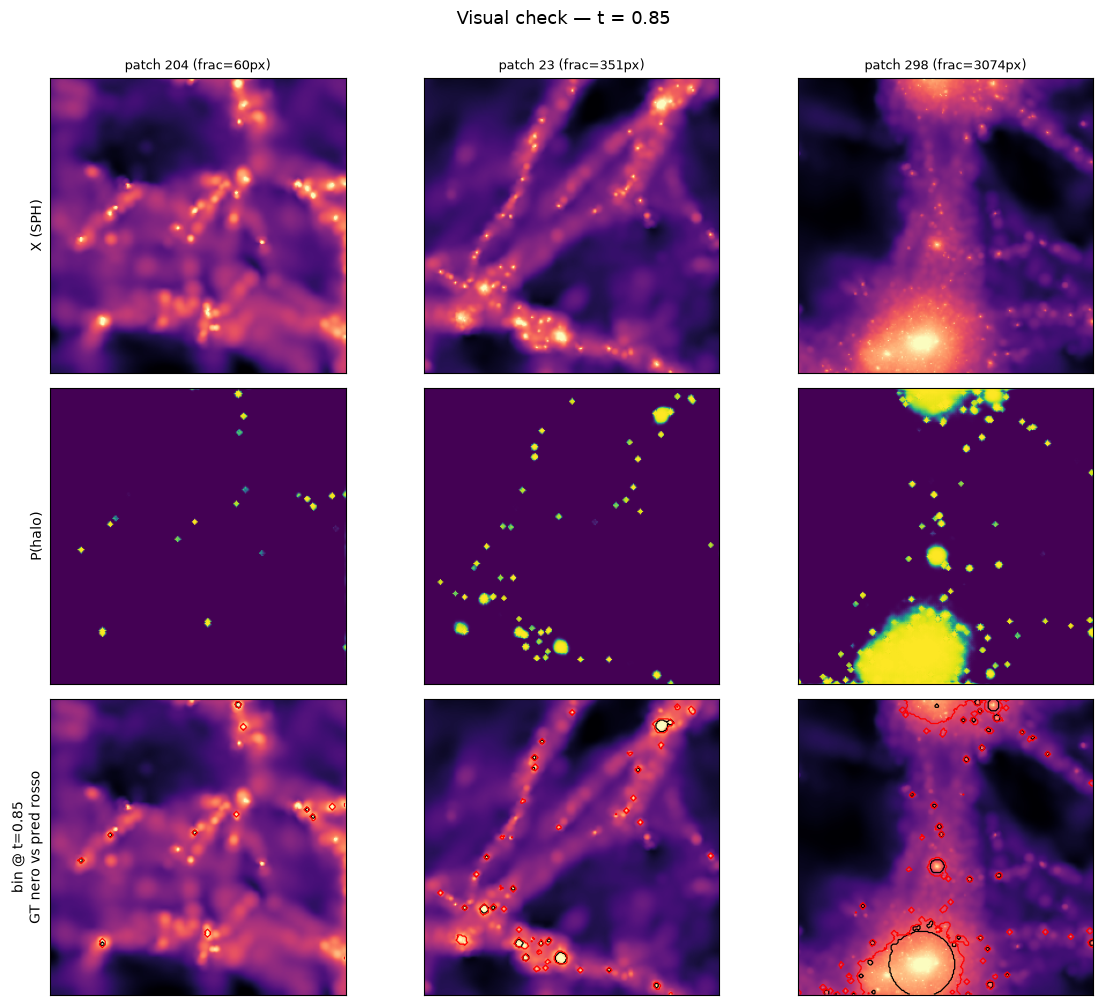

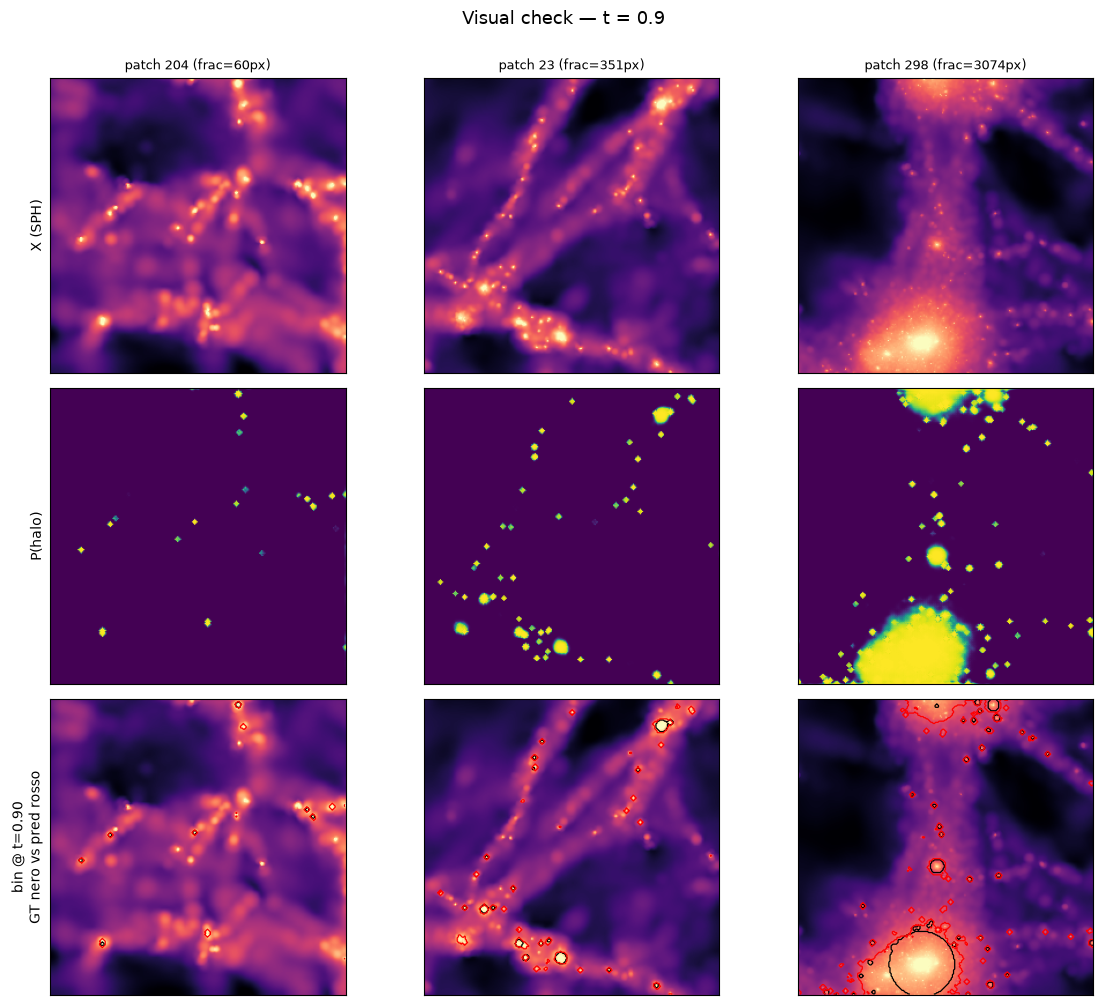

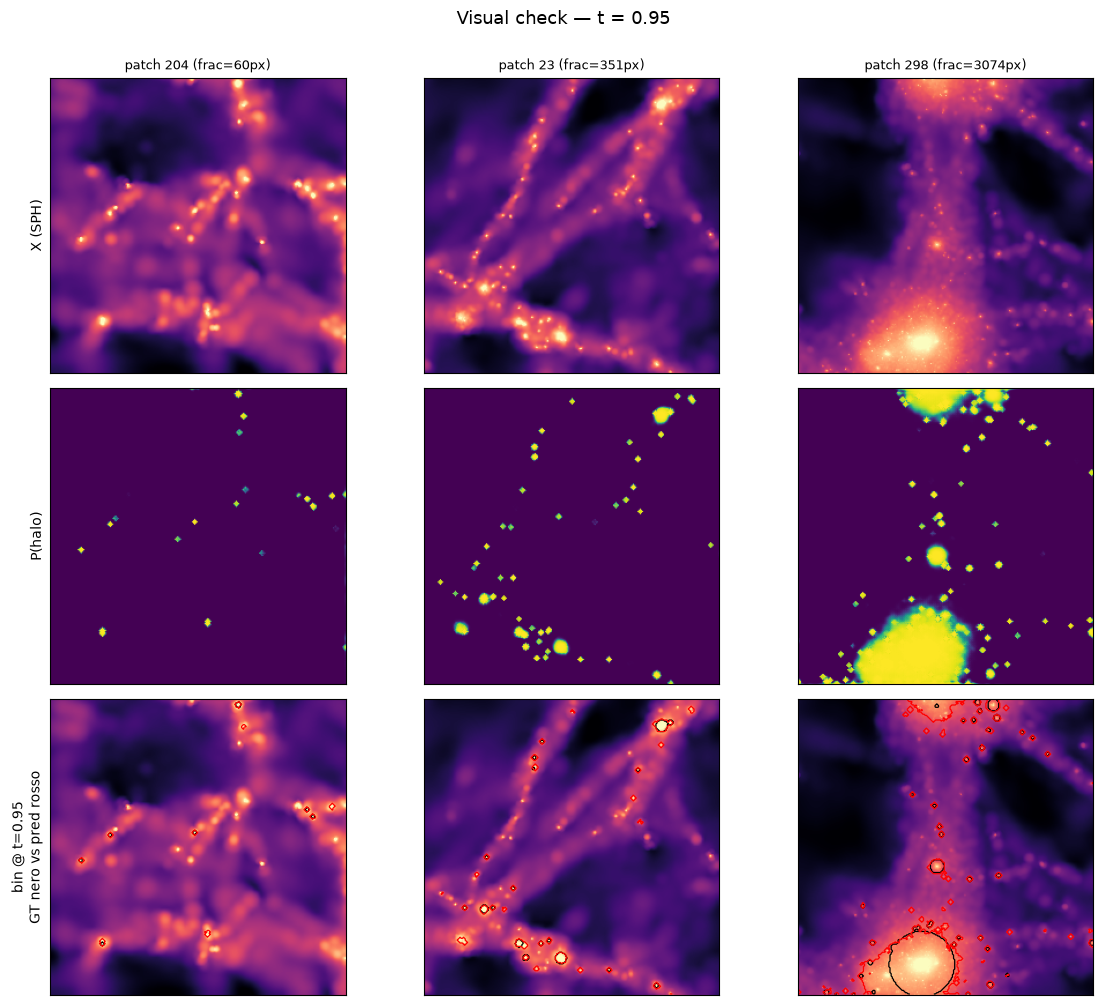

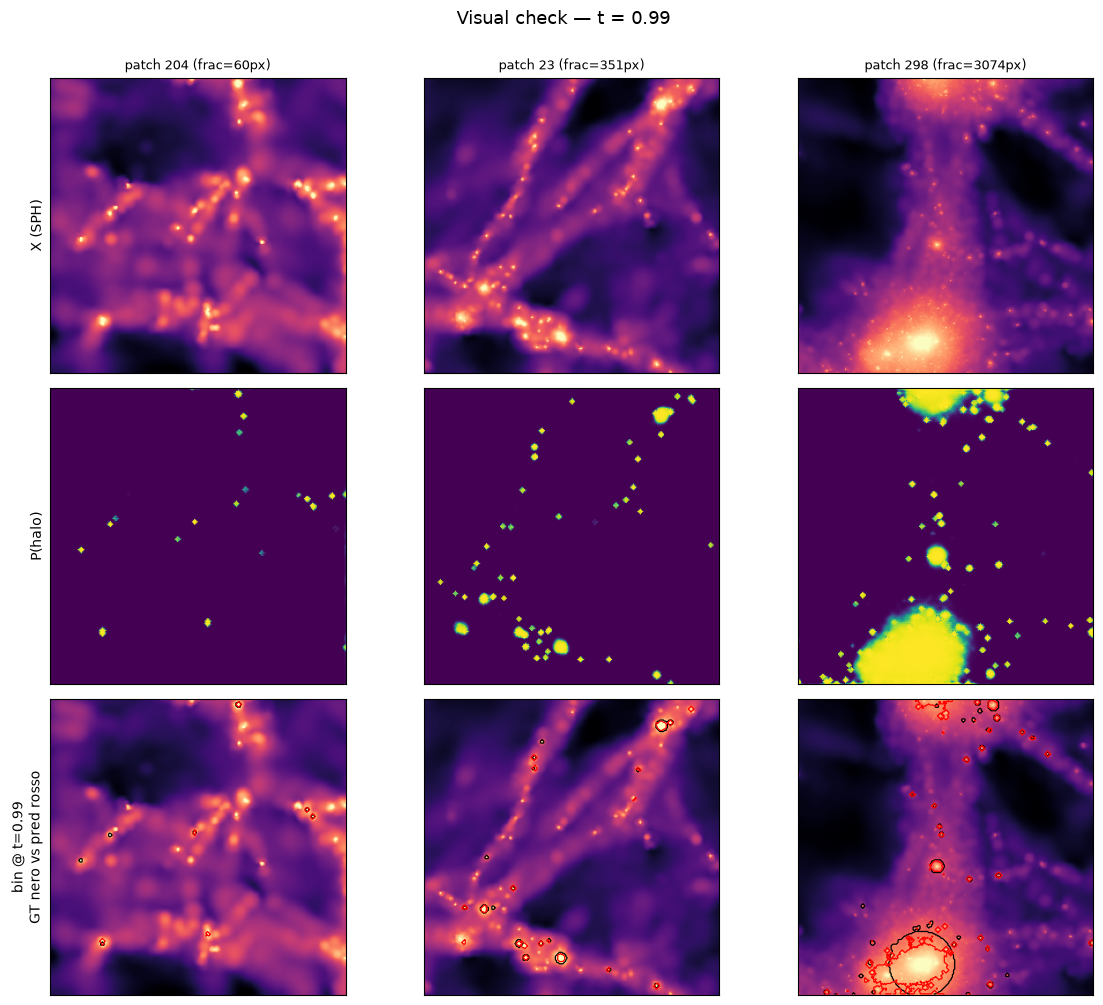

In [12]:
# ============================================================
# 12 — VISUAL CHECK per ogni candidate
# ============================================================
# Per ogni soglia: 3 patch (povera, media, ricca) × 3 righe (X, P, binario+GT vs pred).
# Totale 4 figure, una per soglia. Stesse patch tra soglie → confronto diretto.

frac = data["val"]["Y"].sum(axis=(1, 2, 3))
pos_idx = np.flatnonzero(frac > 0)
ranked  = pos_idx[np.argsort(frac[pos_idx])]
show    = [int(ranked[int(q * (len(ranked) - 1))]) for q in [0.25, 0.75, 1.0]]

for t_show in CANDIDATE_THRESHOLDS:
    fig, axes = plt.subplots(3, len(show), figsize=(4.0 * len(show), 10), squeeze=False)
    for col, idx in enumerate(show):
        x = data["val"]["X"][idx, 0]
        p = probs_val[idx, 0]
        y = data["val"]["Y"][idx, 0]
        vmin, vmax = np.percentile(x, [0.2, 99.8])

        axes[0, col].imshow(x, cmap="magma", vmin=vmin, vmax=vmax)
        axes[0, col].set_title(f"patch {idx} (frac={frac[idx]:.0f}px)", fontsize=9)

        axes[1, col].imshow(p, cmap="viridis", vmin=0, vmax=1)
        axes[1, col].axhline(0, alpha=0)  # placeholder

        axes[2, col].imshow(x, cmap="magma", vmin=vmin, vmax=vmax)
        if y.any():
            axes[2, col].contour(y, levels=[0.5], colors="black", linewidths=0.9)
        if (p > t_show).any():
            axes[2, col].contour((p > t_show).astype(float),
                                 levels=[0.5], colors="red", linewidths=0.9)

    for r in range(3):
        for c in range(len(show)):
            axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[0, 0].set_ylabel("X (SPH)")
    axes[1, 0].set_ylabel("P(halo)")
    axes[2, 0].set_ylabel(f"bin @ t={t_show:.2f}\nGT nero vs pred rosso")
    fig.suptitle(f"Visual check — t = {t_show}", fontsize=13, y=1.0)
    plt.tight_layout(); plt.show()

## 12b. Confronto visivo delle 4 soglie su patch identiche

La sezione §12 mostra una figura per soglia. Questa sezione affianca le 4 soglie **sulle stesse patch**, in un'unica griglia $4 \times 3$: righe = soglie, colonne = patch (povera, media, ricca).

**Perché una figura separata.** Il confronto riga-per-riga rende immediatamente visibile il trade-off:

- a $t = 0.85$ la predizione (rosso) include materia diffusa attorno al GT (nero) e produce frammenti spuri;
- a $t = 0.90$ la sbavatura si riduce ma compaiono ancora frammenti;
- a $t = 0.95$ i contorni rossi seguono da vicino il GT sui core, con perdita di qualche pixel di bordo;
- a $t = 0.99$ la predizione si riduce a pochi pixel centrali, aloni piccoli spariscono.

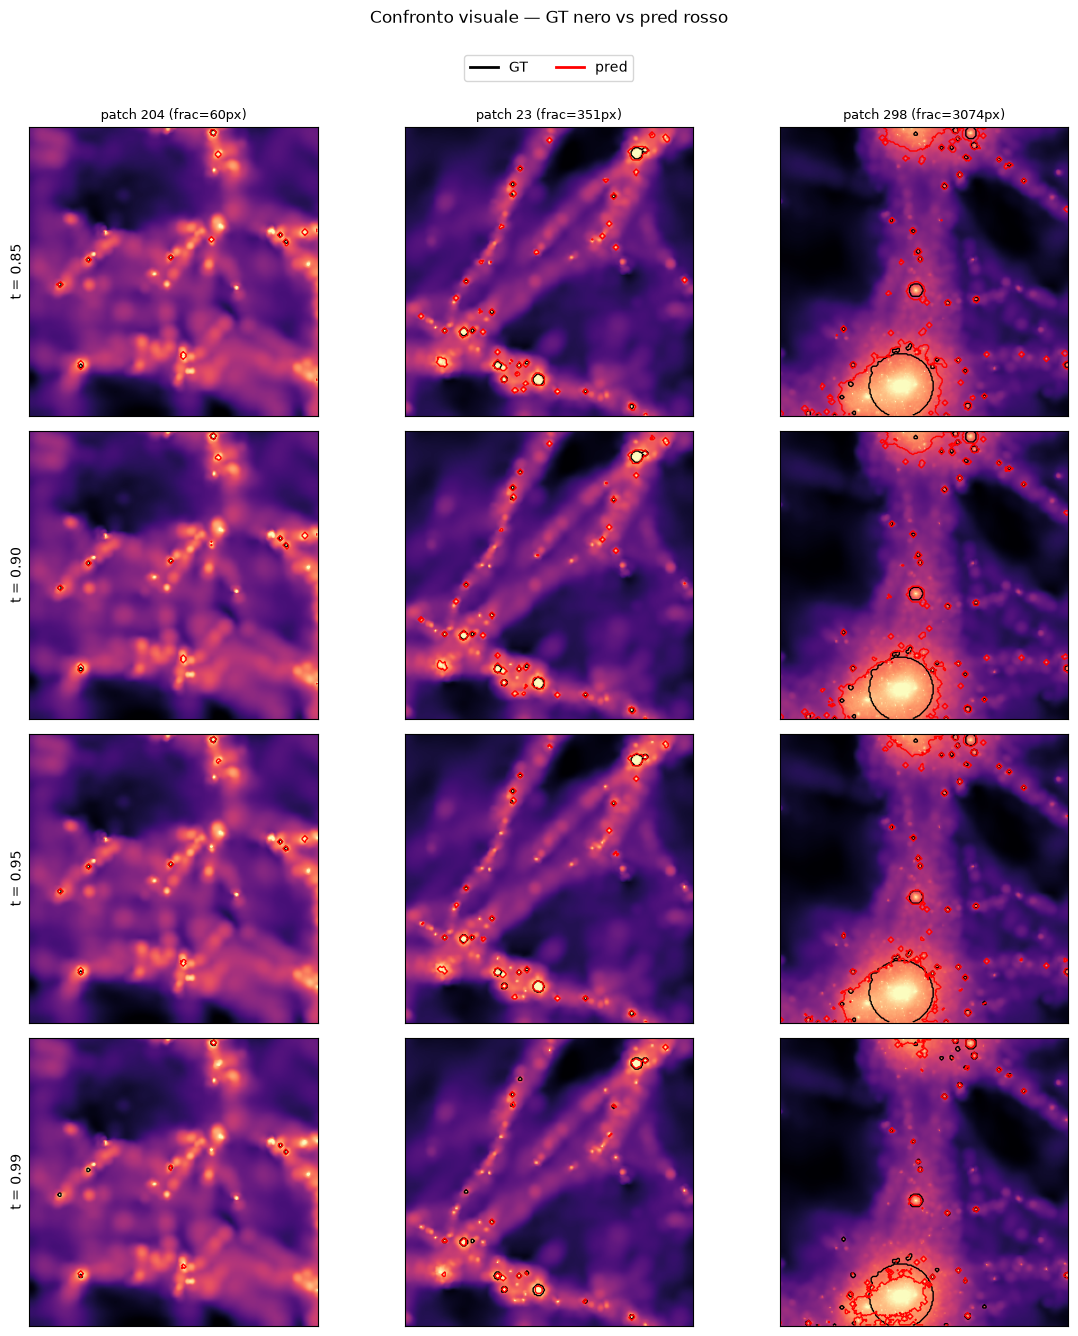

In [14]:
# ============================================================
# 12b — CONFRONTO VISIVO TRA LE 4 SOGLIE
# ============================================================
# Righe = soglie; colonne = le stesse patch del visual check.
# Contorno nero = GT, contorno rosso = predizione.

from matplotlib.lines import Line2D

frac = data["val"]["Y"].sum(axis=(1, 2, 3))
pos_idx = np.flatnonzero(frac > 0)
ranked = pos_idx[np.argsort(frac[pos_idx])]
show = [int(ranked[int(q * (len(ranked) - 1))]) for q in [0.25, 0.75, 1.0]]

fig, axes = plt.subplots(
    len(CANDIDATE_THRESHOLDS), len(show),
    figsize=(4.0 * len(show), 3.2 * len(CANDIDATE_THRESHOLDS)),
    squeeze=False,
)

for row, t_show in enumerate(CANDIDATE_THRESHOLDS):
    for col, idx in enumerate(show):
        x = data["val"]["X"][idx, 0]
        p = probs_val[idx, 0]
        y = data["val"]["Y"][idx, 0].astype(bool)
        vmin, vmax = np.percentile(x, [0.2, 99.8])

        ax = axes[row, col]
        ax.imshow(x, cmap="magma", vmin=vmin, vmax=vmax)
        if y.any():
            ax.contour(y, levels=[0.5], colors="black", linewidths=1.0)
        pred = p > t_show
        if pred.any():
            ax.contour(pred, levels=[0.5], colors="red", linewidths=1.0)
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(f"patch {idx} (frac={frac[idx]:.0f}px)", fontsize=9)
        if col == 0:
            ax.set_ylabel(f"t = {t_show:.2f}", fontsize=10)

fig.legend(
    handles=[
        Line2D([0], [0], color="black", lw=2, label="GT"),
        Line2D([0], [0], color="red", lw=2, label="pred"),
    ],
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.01),
)
fig.suptitle("Confronto visuale — GT nero vs pred rosso", y=1.04)
plt.tight_layout()
plt.show()